# Visualizing potential feature manifolds from labels

In [ ]:
import hashlib

import numpy as np
import plotly.graph_objects as go
import polars as pl

from biomanifolds import config, plots
from biomanifolds.datasets import swissprot
from biomanifolds.embed_sequences import embed_sequences
from biomanifolds.labels import af2_structure_labels, sequence_labels, swissprot_labels

LAYER = 18
EMBEDDINGS_PATHS = {split: config.data_path("esm2_embeddings") / f"sampled_{split}_residue_embeddings_L{LAYER}.npy"
                    for split in SPLITS}


# Helper to sample 10% of the proteins of a split, using the MD5 hash of the accession for reproducibility
def in_sample(accession):
    return int(hashlib.md5(accession.encode()).hexdigest()[:8], 16) / 16**8 < 0.10

# Load sequences for train and test proteins and sample 10% of each split
splits = pl.read_parquet(swissprot.swissprot_dir() / "splits" / "splits.parquet", columns=["accession", "split"])
sequences = pl.read_parquet(swissprot.swissprot_dir() / "swissprot.parquet", columns=["accession", "sequence"])
proteins = {
    split: sequences.join(splits.filter(pl.col("split") == split), on="accession")
    .filter(pl.col("accession").map_elements(in_sample, return_dtype=pl.Boolean))
    .select("accession", "sequence")
    .sort("accession")
    for split in SPLITS
}

embeddings, rows = {}, {}
for split in SPLITS:
    # Generate ESM-2 layer-18 embedding of every residue of these proteins;
    # (train: about 5 minutes on an A100)
    if not EMBEDDINGS_PATHS[split].exists():
        embed_sequences(proteins[split]["sequence"].to_list(), EMBEDDINGS_PATHS[split], LAYER)

    embeddings[split] = np.load(EMBEDDINGS_PATHS[split], mmap_mode="r")  # (residues, 640), float16, read from disk when used
    # row r of `embeddings[split]` is residue i of protein accession: the proteins in order, then their residues in order
    rows[split] = proteins[split].select("accession", i=pl.int_ranges(pl.col("sequence").str.len_chars())).explode("i")
    assert len(rows[split]) == len(embeddings[split])
    print(f"{split}: {len(proteins[split]):,} proteins, {len(embeddings[split]):,} residues, {embeddings[split].shape[1]} dimensions")

train: 41,426 proteins, 13,342,158 residues, 640 dimensions


(null): No such file or directory
(null): No such file or directory


Loading weights:   0%|          | 0/486 [00:00<?, ?it/s]

[transformers] EsmModel LOAD REPORT from: facebook/esm2_t30_150M_UR50D
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


batch 0/197
batch 100/197
test: 8,656 proteins, 3,131,410 residues, 640 dimensions


## Comparing the subset of sampled residues with the full dataset

train sampled: 41,426 of 411,591 proteins (10.1%), 13,342,158 of 132,649,623 residues
test sampled: 8,656 of 86,165 proteins (10.0%), 3,131,410 of 31,378,971 residues


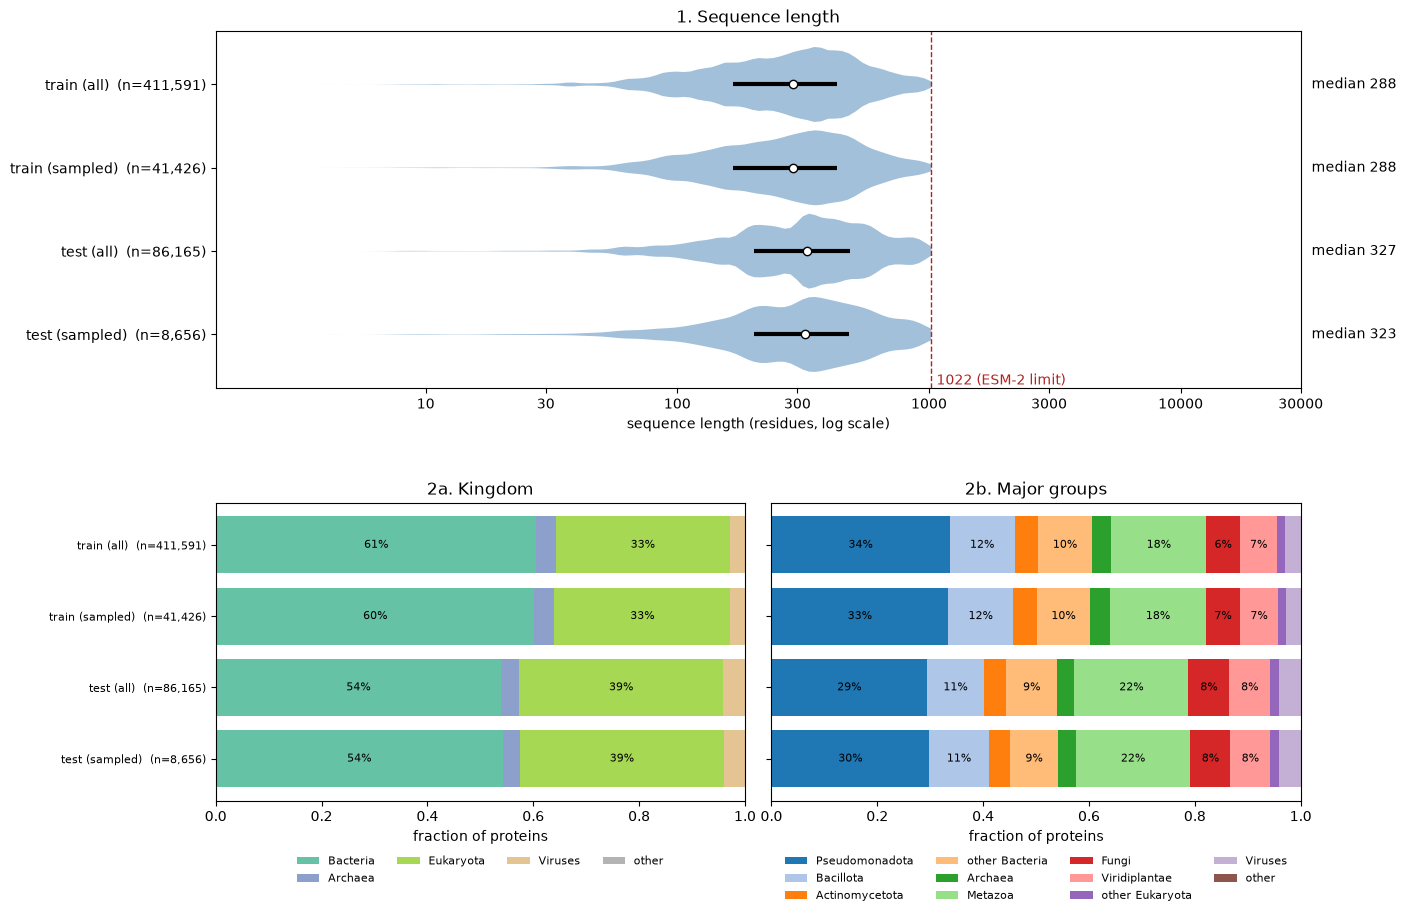

In [12]:
all_proteins = (
    sequence_labels.load_protein_labels()
    .join(swissprot_labels.load_protein_labels().select("accession", "kingdom", "group"), on="accession")
    .join(splits.lazy(), on="accession")
    .collect()
)
groups = {}
for split in SPLITS:
    everything = all_proteins.filter(pl.col("split") == split)
    sampled = everything.filter(pl.col("accession").is_in(proteins[split]["accession"].implode()))
    print(f"{split} sampled: {len(sampled):,} of {len(everything):,} proteins ({len(sampled) / len(everything):.1%}), "
          f"{sampled['length'].sum():,} of {everything['length'].sum():,} residues")
    groups[f"{split} (all)"], groups[f"{split} (sampled)"] = everything, sampled
plots.protein_summary(groups);

## Mean embeddings per label bin
For each label: take all residues that have a value, from 40k proteins sampled off the **train** split; group all residues into bins and compute the means for each bin, leaving out bins with fewer than 200 residues (as in the esm-interp dashboard). Visualize with 3D PCA, print variance explained from further PCs

The slider changes the bin width from 1-4, larger bin widths result in smoother-looking visualisations. 

In [ ]:
MIN_COUNT = 200  # bins with fewer residues are left out

# sum and count of the embeddings per 1-unit bin, for each split and label, saved so that they are only computed once
sums, counts = {}, {}
for split in SPLITS:
    bin_files = {name: config.data_path("label_bins") / f"{split}_{name}_L{LAYER}.npy" for name in [
        "helix_face_1deg_bin_sums", "helix_face_1deg_bin_counts", "plddt_1unit_bin_sums", "plddt_1unit_bin_counts"]}

    if all(path.exists() for path in bin_files.values()):
        helix_sums, helix_counts, plddt_sums, plddt_counts = (np.load(path) for path in bin_files.values())
    else:
        # helix face and pLDDT of every embedding row, in row order (null: no AFDB model, or no value).
        # The 171M-row label table is streamed on the left of the join, so that only the embedding
        # rows are held in memory.
        labels = (
            af2_structure_labels.load_labels(["accession", "i", "helix_face", "plddt"])
            .join(rows[split].with_row_index("row").lazy(), on=["accession", "i"])
            .collect(engine="streaming")
        )
        row_labels = pl.DataFrame({"row": np.arange(len(rows[split]), dtype=np.uint32)}).join(labels, on="row", how="left").sort("row")
        # bin of every row in 1-unit bins, -1 = no value
        #   helix face (-180, 180] degrees -> bins 0..359 (bin k: [k - 180, k - 179), 180 wraps to -180)
        #   pLDDT [0, 100] -> bins 0..100 (bin k: [k, k + 1))
        helix_bins = ((row_labels["helix_face"].floor() + 180) % 360).fill_null(-1).cast(pl.Int64).to_numpy()
        plddt_bins = row_labels["plddt"].floor().fill_null(-1).cast(pl.Int64).to_numpy()

        # sum and count of the embeddings in every bin of width 1, reading the embeddings 1M rows at a time
        helix_sums, helix_counts = np.zeros((360, 640)), np.zeros(360)
        plddt_sums, plddt_counts = np.zeros((101, 640)), np.zeros(101)
        for start in range(0, len(embeddings[split]), 1_000_000):
            x = embeddings[split][start:start + 1_000_000].astype(np.float32)
            for bsums, bcounts, bins in [(helix_sums, helix_counts, helix_bins), (plddt_sums, plddt_counts, plddt_bins)]:
                b = bins[start:start + 1_000_000]
                for k in np.unique(b[b >= 0]):
                    bsums[k] += x[b == k].sum(0)
                    bcounts[k] += (b == k).sum()

        for path, array in zip(bin_files.values(), [helix_sums, helix_counts, plddt_sums, plddt_counts]):
            np.save(path, array)
    sums[split] = {"helix_face": helix_sums, "plddt": plddt_sums}
    counts[split] = {"helix_face": helix_counts, "plddt": plddt_counts}


In [14]:
def bin_means(sums, counts, first_value, width):
    """Mean embedding per bin of `width` neighbouring 1-unit bins, for the bins with at least MIN_COUNT residues:
    means (bins, 640), label value at the centre of each bin, residues per bin, and a text about the dropped bins."""
    firsts = np.arange(0, len(counts), width)
    bin_sums, bin_counts = np.add.reduceat(sums, firsts), np.add.reduceat(counts, firsts)
    keep = bin_counts >= MIN_COUNT
    return {
        "means": bin_sums[keep] / bin_counts[keep, None],
        "centers": first_value + firsts[keep] + width / 2,
        "counts": bin_counts[keep],
        "dropped": f"{(bin_counts == 0).sum()} empty bins, {((bin_counts > 0) & ~keep).sum()} bins with fewer than {MIN_COUNT} residues",
    }


def pca_axes(means, reference=None):
    """PC axes of `means`: their centre, the first 6 components, and the fraction of variance each explains.
    With `reference` (the components of another fit), each PC is flipped to point the same way."""
    center = means.mean(0)
    _, s, vt = np.linalg.svd(means - center, full_matrices=False)
    components = vt[:6]
    if reference is not None:
        components = components * np.sign((components * reference).sum(1))[:, None]
    return {"center": center, "components": components, "explained": (s**2 / (s**2).sum())[:6]}

In [15]:
def plot_pca(points, axes, label, title, periodic=False):
    """3D plot of `points[width]` (from bin_means) projected on `axes[width]` (from pca_axes).
    The slider changes the bin width."""
    widths = list(points)
    fig, steps = go.Figure(), []
    for w, width in enumerate(widths):
        p, a = points[width], axes[width]
        pcs = (p["means"] - a["center"]) @ a["components"][:3].T

        order = np.r_[np.arange(len(pcs)), 0] if periodic else np.arange(len(pcs))  # periodic: close the loop
        fig.add_trace(go.Scatter3d(
            x=pcs[order, 0], y=pcs[order, 1], z=pcs[order, 2], mode="markers+lines", visible=w == 0,
            line=dict(color="lightgray"), hoverinfo="text",
            text=[f"{label} {p['centers'][j]:g}: {p['counts'][j]:,.0f} residues" for j in order],
            marker=dict(size=4, color=p["centers"][order], colorbar=dict(title=label),
                        colorscale="Twilight" if periodic else "Viridis",
                        cmin=-180 if periodic else None, cmax=180 if periodic else None),
        ))
        axis_titles = {f"scene.{x}axis.title.text": f"PC{k + 1} ({a['explained'][k]:.1%})" for k, x in enumerate("xyz")}
        dropped_note = dict(text=f"dropped: {p['dropped']}", x=1, y=0, xref="paper", yref="paper", xanchor="right",
                            yanchor="bottom", showarrow=False, font=dict(size=11, color="gray"))
        layout = {**axis_titles, "annotations": [dropped_note]}
        steps.append(dict(label=str(width), method="update", args=[{"visible": [v == w for v in range(len(widths))]}, layout]))
    fig.update_layout(steps[0]["args"][1], height=650, scene_aspectmode="data",  # aspectmode data: proportional axes
                      title=title, sliders=[dict(steps=steps, currentvalue=dict(prefix="bin width: "))])
    fig.show()

### Helix face

In [18]:
widths = [1, 2, 5, 10]
points = {split: {w: bin_means(sums[split]["helix_face"], counts[split]["helix_face"], -180, w) for w in widths} for split in SPLITS}

# train PC axes for every bin width, saved
axes = {}
for w in widths:
    axes[w] = pca_axes(points["train"][w]["means"], reference=axes[widths[0]]["components"] if axes else None)
    np.savez(config.data_path("label_bins") / f"train_helix_face_width{w}_pca_axes_L{LAYER}.npz", **axes[w])
    print(f"bin width {w}: train PC1-6 explain {np.round(axes[w]['explained'], 3)}")

plot_pca(points["train"], axes, "helix_face", f"Layer {LAYER}: <b>train</b> mean embedding per helix_face bin, on the train PCs", periodic=True)
plot_pca(points["test"], axes, "helix_face", f"Layer {LAYER}: <b>test</b> mean embedding per helix_face bin, on the train PCs", periodic=True)

bin width 1: train PC1-6 explain [0.64  0.233 0.013 0.008 0.007 0.005]
bin width 2: train PC1-6 explain [0.658 0.24  0.013 0.007 0.007 0.005]
bin width 5: train PC1-6 explain [0.676 0.246 0.013 0.007 0.006 0.005]
bin width 10: train PC1-6 explain [0.689 0.251 0.013 0.007 0.006 0.005]


### pLDDT

In [19]:
widths = [1, 2, 5]
points = {split: {w: bin_means(sums[split]["plddt"], counts[split]["plddt"], 0, w) for w in widths} for split in SPLITS}

# train PC axes for every bin width, saved
axes = {}
for w in widths:
    axes[w] = pca_axes(points["train"][w]["means"], reference=axes[widths[0]]["components"] if axes else None)
    np.savez(config.data_path("label_bins") / f"train_plddt_width{w}_pca_axes_L{LAYER}.npz", **axes[w])
    print(f"bin width {w}: train PC1-6 explain {np.round(axes[w]['explained'], 3)}")

plot_pca(points["train"], axes, "plddt", f"Layer {LAYER}: <b>train</b> mean embedding per plddt bin, on the train PCs")
plot_pca(points["test"], axes, "plddt", f"Layer {LAYER}: <b>test</b> mean embedding per plddt bin, on the train PCs")

bin width 1: train PC1-6 explain [0.867 0.09  0.023 0.01  0.004 0.002]
bin width 2: train PC1-6 explain [0.933 0.038 0.016 0.006 0.004 0.001]
bin width 5: train PC1-6 explain [0.932 0.039 0.015 0.007 0.005 0.001]
